# 31 - Phase 3: prospective validation at ~91M params

Notebook 30 committed predictions for ~90M **before any 90M model existed**
(`results/preregistered_90M.csv`). Here we train combo / combo_conv3 / combo_diff at **91.3M params**
(768d, 12L, 12h) under the same fixed protocol (WT103 BPE, block 256, batch 16, 6000 it = 24.6M tokens)
and grade the predictions. Seed 0 first for all variants, then seed 1.

This is the difference between a retrospective curve-fit and a real forecast: either the fits called
the 90M outcome (protocol works at +0.5 decade) or they didn't (a measured limit on extrapolation
range). Both outcomes are findings.


In [1]:
%matplotlib inline
import os, math, time, csv, json, gc
from contextlib import nullcontext
import numpy as np
import torch
from model import Config, GPT, count_params

device = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", device)
D = "../dataset"
train_data = torch.from_numpy(np.load(D + "/wt103_bpe_train.npy"))
val_data = torch.from_numpy(np.load(D + "/wt103_bpe_val.npy"))
vocab = json.load(open(D + "/wt103_bpe_meta.json"))["vocab"]
print(f"vocab={vocab}  train={len(train_data):,}  val={len(val_data):,}")

BLOCK, BATCH = 256, 16
CKPT_DIR = "../results/val90_ckpt"
os.makedirs(CKPT_DIR, exist_ok=True)

COMBO = {"pos_encoding": "rope", "activation": "swiglu", "norm_placement": "pre", "norm_type": "rmsnorm"}
VARIANTS = {"combo": COMBO, "combo_conv3": {**COMBO, "conv_kernel": 3}, "combo_diff": {**COMBO, "attention": "diff"}}
SIZE90 = (768, 12, 12)   # ~91.3M params; measured ~4.7GB at batch16/block256
RUNS_CSV = "../results/val90_runs.csv"
if not os.path.exists(RUNS_CSV):
    with open(RUNS_CSV, "w", newline="") as f:
        csv.writer(f).writerow(["variant", "seed", "params_M", "val_ppl"])

def get_batch(split, gen):
    d = train_data if split == "train" else val_data
    ix = torch.randint(len(d) - BLOCK, (BATCH,), generator=gen)
    x = torch.stack([d[i:i + BLOCK] for i in ix]); y = torch.stack([d[i + 1:i + 1 + BLOCK] for i in ix])
    return x.to(device), y.to(device)
def autocast_ctx():
    return torch.autocast(device_type="cuda", dtype=torch.bfloat16) if device == "cuda" else nullcontext()

def train_one(name, size_cfg, over, seed=0, max_iters=6000, eval_iters=200,
              lr=3e-4, warmup=200, min_lr=3e-5, ckpt_every=500):
    ne, nl, nh = size_cfg
    ckpt_path = f"{CKPT_DIR}/{name}_s{seed}.pt"
    torch.manual_seed(seed)
    cfg = Config(vocab_size=vocab, block_size=BLOCK, n_layer=nl, n_head=nh, n_embd=ne,
                 dropout=0.1, **over)
    model = GPT(cfg).to(device)
    pm = count_params(model) / 1e6
    opt = torch.optim.AdamW(model.parameters(), lr=lr, betas=(0.9, 0.99), weight_decay=0.1)
    tg = torch.Generator().manual_seed(7777 + seed)
    start_it = 0
    if os.path.exists(ckpt_path):
        # load to CPU: Generator.set_state() requires a CPU ByteTensor
        ck = torch.load(ckpt_path, map_location="cpu")
        model.load_state_dict(ck["model"]); opt.load_state_dict(ck["opt"])
        tg.set_state(ck["tg"].cpu()); start_it = ck["iter"]
        print(f"    [{name} s{seed}] RESUMED from {start_it}", flush=True)
    def get_lr(it):
        if it < warmup: return lr * (it + 1) / warmup
        r = (it - warmup) / max(1, max_iters - warmup)
        return min_lr + 0.5 * (lr - min_lr) * (1 + math.cos(math.pi * r))
    def save_ckpt(it):
        tmp = ckpt_path + ".tmp"
        torch.save({"model": model.state_dict(), "opt": opt.state_dict(), "iter": it, "tg": tg.get_state()}, tmp)
        os.replace(tmp, ckpt_path)
    @torch.no_grad()
    def ev():
        model.eval(); g = torch.Generator().manual_seed(4242); tot = 0.0
        for _ in range(eval_iters):
            x, y = get_batch("val", g)
            with autocast_ctx():
                _, loss = model(x, y)
            tot += loss.item()
        model.train(); return tot / eval_iters
    t0 = time.time()
    for it in range(start_it, max_iters):
        for grp in opt.param_groups: grp["lr"] = get_lr(it)
        x, y = get_batch("train", tg)
        with autocast_ctx():
            _, loss = model(x, y)
        opt.zero_grad(set_to_none=True); loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0); opt.step()
        if it % 1000 == 0:
            print(f"    [{name} s{seed}] it {it}/{max_iters} loss {loss.item():.3f} {(time.time()-t0)/60:.1f}m", flush=True)
        if (it + 1) % ckpt_every == 0: save_ckpt(it + 1)
    ppl = math.exp(ev())
    if os.path.exists(ckpt_path): os.remove(ckpt_path)
    del model, opt; gc.collect(); torch.cuda.empty_cache()
    return ppl, pm

def run90(vname, seed):
    done = set()
    with open(RUNS_CSV) as f:
        r = csv.reader(f); next(r, None)
        for row in r:
            if len(row) == 4: done.add((row[0], row[1]))
    if (vname, str(seed)) in done:
        print(f"  90M {vname} s{seed}: done, skip", flush=True); return
    t0 = time.time()
    p, pm = train_one(f"90M_{vname}", SIZE90, VARIANTS[vname], seed=seed)
    with open(RUNS_CSV, "a", newline="") as f:
        csv.writer(f).writerow([vname, seed, f"{pm:.3f}", f"{p:.4f}"])
    print(f"  90M {vname:12s} seed {seed}: ppl {p:.3f} ({pm:.1f}M) | {(time.time()-t0)/60:.1f} min", flush=True)

print("ready")


device: cuda
vocab=8192  train=14,923,628  val=281,169
ready


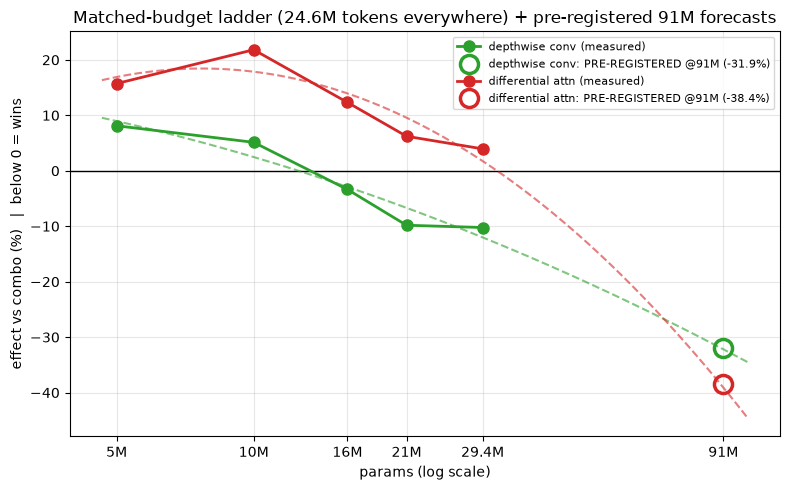

saved ../results/fig_ladder_matched.png


In [2]:
# The matched-budget ladder figure (drawn BEFORE the 90M runs; predictions shown as open markers)
import matplotlib.pyplot as plt

lad = {}
pmd = {}
with open("../results/ladder6000_runs.csv") as f:
    r = csv.reader(f); next(r, None)
    for sz, v, s, pm, pp in r:
        lad[(sz, v, s)] = float(pp); pmd[sz] = float(pm)
def load30(fn):
    d = {}
    with open(fn) as f:
        r = csv.reader(f); next(r, None)
        for row in r:
            if len(row) == 3: d[row[0]] = float(row[2])
    return d
s0m = load30("../results/scale_confirm_runs.csv"); s1m = load30("../results/scale_confirm_s1_runs.csv")
prereg = {}
if os.path.exists("../results/preregistered_90M.csv"):
    with open("../results/preregistered_90M.csv") as f:
        r = csv.reader(f); next(r, None)
        for v, fit, pred in r: prereg[(v, fit)] = float(pred)

order = ["5M", "10M", "15M", "20M"]
colors = {"combo_conv3": "tab:green", "combo_diff": "tab:red"}
labels = {"combo_conv3": "depthwise conv", "combo_diff": "differential attn"}
X30, X90 = math.log10(29.407e6), math.log10(91.3e6)

plt.figure(figsize=(8, 5))
plt.axhline(0, color="k", lw=1)
FITS = {}
for variant in ["combo_conv3", "combo_diff"]:
    xs, ys = [], []
    for sz in order:
        for s in ("0", "1"):
            if (sz, variant, s) in lad and (sz, "combo", s) in lad:
                xs.append(math.log10(pmd[sz] * 1e6))
                ys.append(100.0 * (lad[(sz, variant, s)] - lad[(sz, "combo", s)]) / lad[(sz, "combo", s)])
    for i, dd in ((0, s0m), (1, s1m)):
        xs.append(X30); ys.append(100.0 * (dd[variant] - dd["combo"]) / dd["combo"])
    c = colors[variant]
    szx = sorted(set(xs))
    mean_by_x = [np.mean([y for x_, y in zip(xs, ys) if x_ == x]) for x in szx]
    plt.plot(szx, mean_by_x, "o-", color=c, ms=8, lw=2, label=f"{labels[variant]} (measured)")
    cf2 = np.polyfit(xs, ys, 2)
    FITS[variant] = cf2
    xg = np.linspace(min(xs) - 0.03, X90 + 0.05, 120)
    plt.plot(xg, np.polyval(cf2, xg), "--", color=c, alpha=0.6)
    if (variant, "quadratic") in prereg:
        plt.plot(X90, prereg[(variant, "quadratic")], "o", mfc="none", mec=c, ms=13, mew=2.5,
                 label=f"{labels[variant]}: PRE-REGISTERED @91M ({prereg[(variant,'quadratic')]:+.1f}%)")
ticks = [math.log10(pmd[sz] * 1e6) for sz in order] + [X30, X90]
plt.xticks(ticks, [f"{pmd[sz]:.0f}M" for sz in order] + ["29.4M", "91M"])
plt.xlabel("params (log scale)"); plt.ylabel("effect vs combo (%)   |  below 0 = wins")
plt.title("Matched-budget ladder (24.6M tokens everywhere) + pre-registered 91M forecasts")
plt.legend(fontsize=8); plt.grid(alpha=0.3)
plt.tight_layout(); plt.savefig("../results/fig_ladder_matched.png", dpi=150)
plt.show(); print("saved ../results/fig_ladder_matched.png")


In [3]:
run90("combo", 0)

    [90M_combo s0] it 0/6000 loss 9.161 0.0m


    [90M_combo s0] it 1000/6000 loss 5.165 3.6m


    [90M_combo s0] it 2000/6000 loss 4.418 7.2m


    [90M_combo s0] it 3000/6000 loss 4.082 10.8m


    [90M_combo s0] it 4000/6000 loss 3.914 14.4m


    [90M_combo s0] it 5000/6000 loss 3.497 18.0m


  90M combo        seed 0: ppl 46.327 (91.3M) | 21.8 min


In [4]:
run90("combo_conv3", 0)

    [90M_combo_conv3 s0] it 0/6000 loss 9.164 0.0m


    [90M_combo_conv3 s0] it 1000/6000 loss 4.789 4.0m


    [90M_combo_conv3 s0] it 2000/6000 loss 4.046 8.0m


    [90M_combo_conv3 s0] it 3000/6000 loss 3.780 11.9m


    [90M_combo_conv3 s0] it 4000/6000 loss 3.655 15.9m


    [90M_combo_conv3 s0] it 5000/6000 loss 3.279 19.9m


  90M combo_conv3  seed 0: ppl 41.680 (91.4M) | 24.1 min


In [5]:
run90("combo_diff", 0)

    [90M_combo_diff s0] it 0/6000 loss 9.187 0.0m


    [90M_combo_diff s0] it 1000/6000 loss 5.031 4.9m


    [90M_combo_diff s0] it 2000/6000 loss 4.335 9.8m


    [90M_combo_diff s0] it 3000/6000 loss 4.059 14.7m


    [90M_combo_diff s0] it 4000/6000 loss 3.881 19.6m


    [90M_combo_diff s0] it 5000/6000 loss 3.498 24.4m


  90M combo_diff   seed 0: ppl 47.359 (91.3M) | 29.6 min


In [6]:
run90("combo", 1)

    [90M_combo s1] it 0/6000 loss 9.167 0.0m


    [90M_combo s1] it 1000/6000 loss 5.234 3.6m


    [90M_combo s1] it 2000/6000 loss 4.546 7.2m


    [90M_combo s1] it 3000/6000 loss 4.010 10.8m


    [90M_combo s1] it 4000/6000 loss 3.920 14.4m


    [90M_combo s1] it 5000/6000 loss 3.690 17.9m


  90M combo        seed 1: ppl 46.013 (91.3M) | 21.7 min


In [7]:
run90("combo_conv3", 1)

    [90M_combo_conv3 s1] it 0/6000 loss 9.158 0.0m


    [90M_combo_conv3 s1] it 1000/6000 loss 4.865 4.0m


    [90M_combo_conv3 s1] it 2000/6000 loss 4.215 7.9m


    [90M_combo_conv3 s1] it 3000/6000 loss 3.688 11.9m


    [90M_combo_conv3 s1] it 4000/6000 loss 3.648 15.9m


    [90M_combo_conv3 s1] it 5000/6000 loss 3.464 19.9m


  90M combo_conv3  seed 1: ppl 41.560 (91.4M) | 24.1 min


In [8]:
run90("combo_diff", 1)

    [90M_combo_diff s1] it 0/6000 loss 9.148 0.0m


    [90M_combo_diff s1] it 1000/6000 loss 5.135 4.9m


    [90M_combo_diff s1] it 2000/6000 loss 4.456 9.8m


    [90M_combo_diff s1] it 3000/6000 loss 3.980 14.7m


    [90M_combo_diff s1] it 4000/6000 loss 3.877 19.5m


    [90M_combo_diff s1] it 5000/6000 loss 3.665 24.4m


  90M combo_diff   seed 1: ppl 46.352 (91.3M) | 29.6 min


In [9]:
# === GRADE the pre-registered predictions (uses whatever seeds have finished) ===
v90 = {}
with open(RUNS_CSV) as f:
    r = csv.reader(f); next(r, None)
    for v, s, pm, pp in r: v90[(v, s)] = float(pp)
print("=== 91M results (fixed protocol: 24.6M tokens) ===")
for (v, s), p in sorted(v90.items()): print(f"  {v:12s} s{s}: ppl {p:.3f}")
print()
graded = []
for variant, label in [("combo_conv3", "depthwise conv"), ("combo_diff", "differential attn")]:
    ds = [100.0 * (v90[(variant, s)] - v90[("combo", s)]) / v90[("combo", s)]
          for s in ("0", "1") if (variant, s) in v90 and ("combo", s) in v90]
    if not ds:
        print(f"  {label}: no completed seed pairs yet"); continue
    act = float(np.mean(ds))
    pl, pq = prereg.get((variant, "linear")), prereg.get((variant, "quadratic"))
    print(f"  {label} @91M:  ACTUAL {act:+.2f}%  ({len(ds)} seed(s))")
    if pl is not None: print(f"    pre-registered linear    {pl:+.2f}%   err {pl-act:+.2f}pp" +
                             ("  sign OK" if (pl < 0) == (act < 0) else "  SIGN WRONG"))
    if pq is not None: print(f"    pre-registered quadratic {pq:+.2f}%   err {pq-act:+.2f}pp" +
                             ("  sign OK" if (pq < 0) == (act < 0) else "  SIGN WRONG"))
    graded.append((variant, act, pl, pq, len(ds)))
with open("../results/validation90_graded.csv", "w", newline="") as f:
    w = csv.writer(f); w.writerow(["variant", "actual_pct", "pred_linear_pct", "pred_quad_pct", "n_seeds"])
    for row in graded: w.writerow([row[0], f"{row[1]:.3f}", row[2], row[3], row[4]])
print("\nsaved ../results/validation90_graded.csv")


=== 91M results (fixed protocol: 24.6M tokens) ===
  combo        s0: ppl 46.327
  combo        s1: ppl 46.013
  combo_conv3  s0: ppl 41.680
  combo_conv3  s1: ppl 41.560
  combo_diff   s0: ppl 47.359
  combo_diff   s1: ppl 46.352

  depthwise conv @91M:  ACTUAL -9.85%  (2 seed(s))
    pre-registered linear    -24.76%   err -14.90pp  sign OK
    pre-registered quadratic -31.89%   err -22.04pp  sign OK
  differential attn @91M:  ACTUAL +1.48%  (2 seed(s))
    pre-registered linear    -3.90%   err -5.38pp  SIGN WRONG
    pre-registered quadratic -38.40%   err -39.88pp  SIGN WRONG

saved ../results/validation90_graded.csv


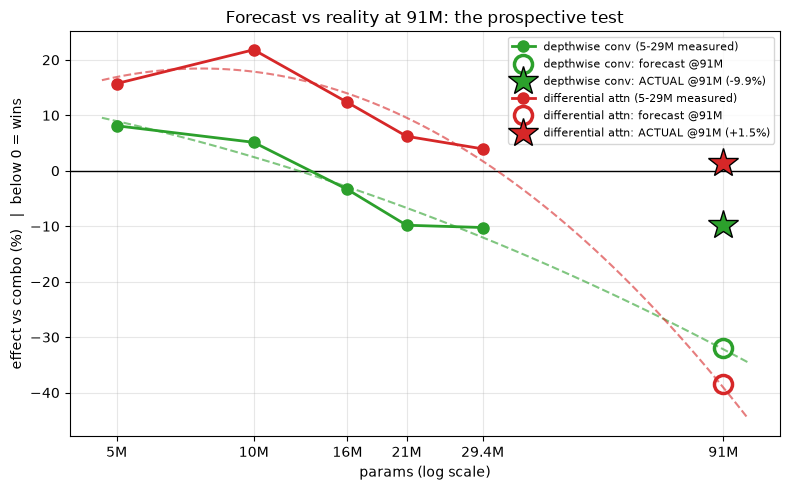

saved ../results/fig_validate90.png


In [10]:
# Final figure: ladder + forecasts + 91M ACTUALS
plt.figure(figsize=(8, 5))
plt.axhline(0, color="k", lw=1)
for variant in ["combo_conv3", "combo_diff"]:
    xs, ys = [], []
    for sz in order:
        for s in ("0", "1"):
            if (sz, variant, s) in lad and (sz, "combo", s) in lad:
                xs.append(math.log10(pmd[sz] * 1e6))
                ys.append(100.0 * (lad[(sz, variant, s)] - lad[(sz, "combo", s)]) / lad[(sz, "combo", s)])
    for i, dd in ((0, s0m), (1, s1m)):
        xs.append(X30); ys.append(100.0 * (dd[variant] - dd["combo"]) / dd["combo"])
    c = colors[variant]
    szx = sorted(set(xs))
    mean_by_x = [np.mean([y for x_, y in zip(xs, ys) if x_ == x]) for x in szx]
    plt.plot(szx, mean_by_x, "o-", color=c, ms=8, lw=2, label=f"{labels[variant]} (5-29M measured)")
    xg = np.linspace(min(xs) - 0.03, X90 + 0.05, 120)
    plt.plot(xg, np.polyval(FITS[variant], xg), "--", color=c, alpha=0.6)
    if (variant, "quadratic") in prereg:
        plt.plot(X90, prereg[(variant, "quadratic")], "o", mfc="none", mec=c, ms=13, mew=2.5,
                 label=f"{labels[variant]}: forecast @91M")
    ds = [100.0 * (v90[(variant, s)] - v90[("combo", s)]) / v90[("combo", s)]
          for s in ("0", "1") if (variant, s) in v90 and ("combo", s) in v90]
    if ds:
        plt.plot(X90, np.mean(ds), "*", color=c, ms=22, mec="k",
                 label=f"{labels[variant]}: ACTUAL @91M ({np.mean(ds):+.1f}%)")
ticks = [math.log10(pmd[sz] * 1e6) for sz in order] + [X30, X90]
plt.xticks(ticks, [f"{pmd[sz]:.0f}M" for sz in order] + ["29.4M", "91M"])
plt.xlabel("params (log scale)"); plt.ylabel("effect vs combo (%)   |  below 0 = wins")
plt.title("Forecast vs reality at 91M: the prospective test")
plt.legend(fontsize=8); plt.grid(alpha=0.3)
plt.tight_layout(); plt.savefig("../results/fig_validate90.png", dpi=150)
plt.show(); print("saved ../results/fig_validate90.png")


## Reading this

If the quadratic forecasts land near the 91M actuals (sign right, error a few pp), the ladder
protocol extrapolates half a decade beyond its data - a usable tool. If they miss, we have a
measured, honest limit on extrapolation range. Combined with notebook 30's rung-subset table
("2 linear rungs = sign-wrong"), either outcome completes the paper's story.
